# MHW maps — Portugal, OISST 1982–2025

Maps of MHW frequency, duration and intensity for the NW, SW and S zones, from the annual summary CSVs of every bathymetry band (200–1000 m).

- **Zones:** NW Minho (41°52′N) – Cabo Carvoeiro (39°21′38″N); SW Cabo Carvoeiro – Sagres (36°59′40″N, 8°56′57″W); S Sagres – Vila Real de Santo António (7°25′W). The strip width offshore is schematic, not the bathymetry mask.
- **Isobaths:** 200, 400, 600, 800 and 1000 m contours on every map; the band each figure is about is solid and dark. Set `BATHY_FILE` to your GEBCO/ETOPO NetCDF to get all five; without it, Natural Earth only gives 200 m and 1000 m.
- **Figure 1** is made for 200 m and 1000 m (`FIG1_DEPTHS`), **Figure 3** for 200 m and 800 m (`FIG3_DEPTHS`); **Figures 2 and 4** cover every depth file found.

Requires `cartopy`, `contourpy`, `shapely`, `scipy`, `pandas`, `matplotlib`, and `xarray` + `netCDF4` if you use `BATHY_FILE`. The first run downloads the Natural Earth coastline once; after that it is cached.

In [1]:
import glob, re, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Polygon as MplPoly
import cartopy.io.shapereader as shpreader
import contourpy
from shapely.geometry import box, Polygon, shape
from shapely.ops import unary_union
from scipy import stats

%matplotlib inline

## Settings
Edit the paths marked `>>> EDIT`. Change `RAMP` for another colour scale.

In [2]:
DATA_DIR = "/Users/miguelsilveira/Documents/GitHub/marineheatwaves/DATA/OUTPUT"  # >>> EDIT: folder with the annual summary CSVs
OUT = "DATA/OUTPUT"                                     # >>> EDIT: where the PNGs are saved

# Zone polygons used in the analysis, one shapefile per bathymetry band (3 polygons each: NW, SW, S).
# When a band has a shapefile, its zones are drawn exactly from it. Only the .shp is needed;
# zones are identified by latitude (northernmost = NW, southernmost = S).
ZONE_SHAPEFILES = {                           # >>> EDIT paths
    200: "/Users/miguelsilveira/Documents/GitHub/marineheatwaves/200m/200m.shp",
    800: "/Users/miguelsilveira/Documents/GitHub/marineheatwaves/601_800m/601_800m.shp",
}

# Isobath contours drawn on every map. The band a figure is about is drawn solid and dark;
# the others are thin dashed grey.
ISOBATHS = [200, 400, 600, 800, 1000]
# Natural Earth isobaths are approximate, so by default they are only drawn when BATHY_FILE is set.
DRAW_ISOBATHS = None                          # None = only with BATHY_FILE; True/False to force

# Bathymetry grid used for the contours (GEBCO or ETOPO NetCDF, the one you used for the masks).
# If None, Natural Earth is used instead, which only has the 200 m and 1000 m isobaths.
BATHY_FILE = None                             # >>> EDIT, e.g. ".../GEBCO_2024_Portugal.nc"
BATHY_VAR = None                              # variable name; None = auto-detect (elevation, z, depth, ...)

# Depths that get their own Figure 1 and Figure 3 (Figures 2 and 4 cover every depth found).
FIG1_DEPTHS = [200, 1000]
FIG3_DEPTHS = [200, 800]

# Depths for the Sen slope table (trend per decade, 95% CI, Mann–Kendall test).
SLOPE_DEPTHS = [200, 800]

# Periods for Figure 4, counted back from the last year so the most recent period is complete
# (5 = half-decades, 10 = decades). The leftover years at the start form a shorter first period.
PERIOD_YEARS = 5
KEEP_SHORT_FIRST_PERIOD = True               # False = drop the leftover years at the start

RAMP = ["#fde6d8", "#f9c4a6", "#f39b6f", "#eb6834", "#c94f20", "#9c3b16", "#6b2810"]   # orange, light -> dark
CMAP = LinearSegmentedColormap.from_list("seq", RAMP)
INK, MUTED, LAND, SEA = "#1f1f1f", "#6b6b6b", "#e4e2dd", "#ffffff"
ISO_FAINT, ISO_STRONG = "#8c8c8c", "#2b2b2b"

## Load data

In [3]:
D = {}
for f in sorted(glob.glob(f"{DATA_DIR}/MHW_annual_summary_wide_oisst.19812025.Portugal_*m_bathymetry.csv")):
    d = int(re.search(r"(\d+)m_bathymetry", f).group(1))
    D[d] = pd.read_csv(f)
D = {d: df[df.Year >= 1982].reset_index(drop=True) for d, df in sorted(D.items())}  # 1981 is a partial OISST year
print("Depths loaded:", list(D))

# Flag bathymetry files that are exact copies of another (e.g. 800 m and 1000 m)
SAME_AS = {}
for i, a in enumerate(D):
    for b in list(D)[:i]:
        if D[a].equals(D[b]):
            SAME_AS[a] = b
            print(f"Note: the {a} m file is identical to the {b} m file.")

def summarise(df, var):
    out = {}
    for z, s in df.groupby("Zone"):
        s = s.sort_values("Year").dropna(subset=[var])
        out[z] = dict(early=s[s.Year <= 2003][var].mean(), late=s[s.Year >= 2004][var].mean(),
                      sen=stats.theilslopes(s[var], s.Year)[0] * 10,
                      p=stats.kendalltau(s.Year, s[var])[1])
    return out

def make_periods(first, last, n, keep_short):
    periods, end = [], last
    while end >= first:
        start = max(first, end - n + 1)
        if end - start + 1 == n or keep_short:
            periods.append((start, end))
        end = start - 1
    return periods[::-1]

PERIODS = make_periods(1982, 2025, PERIOD_YEARS, KEEP_SHORT_FIRST_PERIOD)
print("Periods:", PERIODS)

def decadal(df):
    out = {}
    for a, b in PERIODS:
        r = {}
        for z, g in df[df.Year.between(a, b)].groupby("Zone"):
            n = g.number_of_events
            r[z] = dict(freq=g.mean_n_events.mean(),                       # years with no events count as 0
                        dur=(g.mean_duration_days * n).sum() / n.sum(),    # event-weighted
                        inten=(g.mean_intensity_degC * n).sum() / n.sum())
        out[(a, b)] = r
    return out

def same_note(depth):
    return f" (identical to {SAME_AS[depth]} m)" if depth in SAME_AS else ""

Depths loaded: [200, 400, 600, 800, 1000]
Note: the 1000 m file is identical to the 800 m file.
Periods: [(1982, 1985), (1986, 1990), (1991, 1995), (1996, 2000), (2001, 2005), (2006, 2010), (2011, 2015), (2016, 2020), (2021, 2025)]


## Sen slopes: rate of change per decade
Table of the trend for 1982–2025 in each zone, for the depths in `SLOPE_DEPTHS`. Duration and intensity skip years with no events. Saved as a CSV in `OUT`.

In [4]:
METRICS = {"mean_n_events": ("Frequency", "events/cell/decade"),
           "mean_duration_days": ("Duration", "days/decade"),
           "mean_intensity_degC": ("Intensity", "°C/decade")}

def sen_table(depths):
    rows = []
    for depth in depths:
        if depth not in D:
            print(f"No data for {depth} m; skipped.")
            continue
        for var, (name, unit) in METRICS.items():
            for z in ["NW", "SW", "S"]:
                s = D[depth][D[depth].Zone == z].dropna(subset=[var]).sort_values("Year")
                slope, _, lo, hi = stats.theilslopes(s[var], s.Year, alpha=0.95)
                tau, p = stats.kendalltau(s.Year, s[var])
                rows.append({"depth_m": depth, "metric": name, "zone": z,
                             "sen_slope_per_decade": slope * 10, "ci95_low": lo * 10, "ci95_high": hi * 10,
                             "mk_tau": tau, "mk_p": p, "significant": p < 0.05,
                             "n_years": len(s), "unit": unit})
    return pd.DataFrame(rows)

sen = sen_table(SLOPE_DEPTHS)
sen.to_csv(f"{OUT}/sen_slopes_{'_'.join(f'{d}m' for d in SLOPE_DEPTHS)}.csv", index=False, float_format="%.4f")

# Side-by-side view: one row per metric and zone, one column per depth
def _fmt(r):
    return f"{r.sen_slope_per_decade:+.3f} [{r.ci95_low:+.3f}, {r.ci95_high:+.3f}]{'*' if r.significant else ''}"
sen_wide = (sen.assign(value=sen.apply(_fmt, axis=1), depth=sen.depth_m.astype(str) + " m")
               .pivot_table(index=["metric", "unit", "zone"], columns="depth", values="value", aggfunc="first")
               .reindex(["Frequency", "Duration", "Intensity"], level=0)
               .reindex(["NW", "SW", "S"], level=2))
print("Sen slope per decade [95% CI], * = Mann–Kendall p < 0.05")
sen_wide

Sen slope per decade [95% CI], * = Mann–Kendall p < 0.05


depth                                                 200 m  \
metric    unit               zone                             
Frequency events/cell/decade NW    +0.632 [+0.313, +0.829]*   
                             SW    +0.495 [+0.139, +0.741]*   
                             S     +0.625 [+0.263, +1.000]*   
Duration  days/decade        NW    +1.641 [+0.385, +2.937]*   
                             SW     +1.265 [-0.233, +2.748]   
                             S     +2.505 [+1.180, +3.913]*   
Intensity °C/decade          NW     +0.028 [-0.036, +0.080]   
                             SW     +0.001 [-0.056, +0.050]   
                             S      +0.007 [-0.081, +0.077]   

depth                                                 800 m  
metric    unit               zone                            
Frequency events/cell/decade NW    +0.679 [+0.358, +0.924]*  
                             SW    +0.556 [+0.210, +0.777]*  
                             S     +0.828 [+0.519, +1.214]*  
Duration  days/decade        NW    +1.666 [+0.385, +2.833]*  
                             SW     +1.400 [-0.059, +2.903]  
                             S     +3.011 [+1.668, +4.289]*  
Intensity °C/decade          NW     +0.015 [-0.045, +0.074]  
                             SW     -0.016 [-0.065, +0.042]  
                             S      -0.051 [-0.114, +0.017]

## Coastline, isobaths and zones
Isobath contours come from `BATHY_FILE` if set, otherwise from Natural Earth (200 m and 1000 m only).

In [5]:
DOMAIN = box(-11.2, 35.5, -5.5, 42.6)
CLIP = box(-13, 34, -4, 44)          # larger than the map, so clipping edges stay off-screen

_land_shp = shpreader.natural_earth(resolution="10m", category="physical", name="land")
land = unary_union([g.intersection(DOMAIN) for g in shpreader.Reader(_land_shp).geometries()
                    if g.intersects(DOMAIN)]).buffer(0)

def isobaths_from_grid(path, var, depths):
    import xarray as xr
    ds = xr.open_dataset(path)
    if var is None:
        var = next(v for v in ["elevation", "z", "depth", "topo", "Band1", "bathymetry"] if v in ds)
    da = ds[var]
    lat = next(c for c in da.dims if c.lower().startswith("lat") or c.lower() == "y")
    lon = next(c for c in da.dims if c.lower().startswith("lon") or c.lower() == "x")
    da = da.sortby(lat).sortby(lon).sel({lat: slice(34, 44), lon: slice(-13, -4)})
    z = da.values.astype(float)
    depth = -z if np.nanmedian(z) < 0 else z          # make depth positive downward
    gen = contourpy.contour_generator(da[lon].values, da[lat].values, depth,
                                      fill_type=contourpy.FillType.OuterOffset)
    lines = {d: [l for l in gen.lines(d) if len(l) > 10] for d in depths}
    bands = {}
    for d in depths:                      # sea between the coast (0 m) and the d m isobath
        pts, offs = gen.filled(0.0, float(d))
        polys = []
        for p_, o_ in zip(pts, offs):
            rings = [p_[o_[i]:o_[i + 1]] for i in range(len(o_) - 1)]
            if len(rings[0]) >= 4:
                polys.append(Polygon(rings[0], [r for r in rings[1:] if len(r) >= 4]))
        bands[d] = unary_union(polys).buffer(0) if polys else None
    return lines, bands

def isobaths_from_natural_earth(depths):
    names = {200: "K_200", 1000: "J_1000", 2000: "I_2000", 3000: "H_3000"}
    out, bands = {}, {}
    for d in depths:
        if d not in names:
            print(f"Natural Earth has no {d} m isobath; set BATHY_FILE to draw it.")
            continue
        f = shpreader.natural_earth(resolution="10m", category="physical", name=f"bathymetry_{names[d]}")
        geom = unary_union([g.intersection(CLIP) for g in shpreader.Reader(f).geometries() if g.intersects(CLIP)])
        b = geom.boundary.difference(CLIP.exterior.buffer(1e-6))
        out[d] = [np.array(l.coords) for l in getattr(b, "geoms", [b]) if l.length > 0.05]
        bands[d] = CLIP.difference(geom).buffer(0)       # everything shallower than d (land removed later)
    return out, bands

import shapefile as pyshp

def zones_from_shapefile(path):
    with open(path, "rb") as fh:
        polys = [shape(sh.__geo_interface__).buffer(0) for sh in pyshp.Reader(shp=fh).iterShapes()]
    polys = sorted(polys, key=lambda g: g.centroid.y, reverse=True)      # north -> south
    if len(polys) != 3:
        raise ValueError(f"{path}: expected 3 polygons (NW, SW, S), found {len(polys)}")
    return dict(zip(["NW", "SW", "S"], polys))

import os
_missing = {d: p_ for d, p_ in ZONE_SHAPEFILES.items() if not os.path.exists(p_)}
if _missing:
    raise FileNotFoundError(
        "Shapefile(s) not found — fix the paths in ZONE_SHAPEFILES (Settings cell) and re-run from the top:\n"
        + "\n".join(f"  {d} m: {p_}" for d, p_ in _missing.items()))
ZONES_FROM_SHP = {d: zones_from_shapefile(p_) for d, p_ in ZONE_SHAPEFILES.items()}
for _d, _z in ZONES_FROM_SHP.items():
    print(f"{_d} m zones read from shapefile:",
          {k: f"{g.bounds[1]:.2f}–{g.bounds[3]:.2f}°N" for k, g in _z.items()})

_draw_iso = (BATHY_FILE is not None) if DRAW_ISOBATHS is None else DRAW_ISOBATHS
try:
    ISO_LINES, BAND_POLY = (isobaths_from_grid(BATHY_FILE, BATHY_VAR, ISOBATHS) if BATHY_FILE
                            else isobaths_from_natural_earth(ISOBATHS))
except Exception as e:
    print(f"Could not load isobaths ({e}); maps are drawn without them.")
    ISO_LINES, BAND_POLY = {}, {}
ISO_SOURCE = "bathymetry grid" if BATHY_FILE else "Natural Earth"
if not _draw_iso:
    ISO_LINES = {}
print("Isobaths drawn:", [d for d, l in ISO_LINES.items() if l])

land_c = land.buffer(0.1).buffer(-0.1)            # close estuaries (Tagus, Sado)
strip = land_c.buffer(0.32).difference(land_c)    # schematic coastal band, used only if no isobath is available

# Zone limits:
#   NW: Minho (41°52'N) to Cabo Carvoeiro (39°21'38"N)
#   SW: Cabo Carvoeiro to Sagres (36°59'40"N, 8°56'57"W)
#   S : Sagres to Vila Real de Santo António (7°25'W)
MINHO, CARVOEIRO = 41 + 52/60, 39 + 21/60 + 38/3600
SAGRES_LAT, SAGRES_LON = 36 + 59/60 + 40/3600, -(8 + 56/60 + 57/3600)
VRSA_LON = -(7 + 25/60)
ZBOX = {"NW": box(-11, CARVOEIRO, -8.0, MINHO),
        "SW": unary_union([box(-11, SAGRES_LAT, -8.6, CARVOEIRO),     # west coast
                           box(-11, 36.0, SAGRES_LON, SAGRES_LAT)]),  # deep water off the cape
        "S":  box(SAGRES_LON, 36.0, VRSA_LON, 37.3)}

def make_zones(area):
    sea = area.difference(land_c)
    z = {k: sea.intersection(b) for k, b in ZBOX.items()}
    z["SW"] = z["SW"].difference(z["S"])
    return z

ZONES_BY_DEPTH = {d: make_zones(BAND_POLY[d]) for d in ISOBATHS if BAND_POLY.get(d) is not None}
ZONES_BY_DEPTH.update(ZONES_FROM_SHP)                      # shapefiles take priority
ZONES_SCHEMATIC = make_zones(strip)
print("Zones drawn from shapefiles or isobaths for:", list(ZONES_BY_DEPTH),
      "| schematic strip for:", [d for d in D if d not in ZONES_BY_DEPTH])

def zones_for(depth):
    return ZONES_BY_DEPTH.get(depth, ZONES_SCHEMATIC)

LABEL_XY = {"NW": (-10.3, 40.7), "SW": (-10.3, 38.0), "S": (-6.7, 36.55)}

200 m zones read from shapefile: {'NW': '39.10–41.87°N', 'SW': '36.82–39.10°N', 'S': '36.82–37.19°N'}
800 m zones read from shapefile: {'NW': '39.10–41.87°N', 'SW': '36.84–39.10°N', 'S': '36.36–37.19°N'}
Natural Earth has no 400 m isobath; set BATHY_FILE to draw it.
Natural Earth has no 600 m isobath; set BATHY_FILE to draw it.
Natural Earth has no 800 m isobath; set BATHY_FILE to draw it.
Isobaths drawn: []
Zones drawn from shapefiles or isobaths for: [200, 1000, 800] | schematic strip for: [400, 600]


## Map helpers

In [6]:
def draw_map(ax, values, norm, fmt, title, pvals=None, fs=9, band=None, show_key=True, cmap=None):
    cmap = cmap or CMAP
    """One map: land, zone strips coloured by value, isobaths, labels.
    band = the bathymetry band this panel shows; its isobath is drawn solid and dark."""
    ax.set_facecolor(SEA)
    for g in getattr(land, "geoms", [land]):
        if g.area > 0.01:
            ax.add_patch(MplPoly(np.array(g.exterior.coords), fc=LAND, ec="#9a9893", lw=0.5, zorder=1))
    zones = zones_for(band)
    for z, geom in zones.items():
        ns = pvals is not None and pvals[z] >= 0.05
        for g in getattr(geom, "geoms", [geom]):
            if g.area < 1e-4:
                continue
            ax.add_patch(MplPoly(np.array(g.exterior.coords), fc=cmap(norm(values[z])), ec="white",
                                 lw=1.5, zorder=2, alpha=0.45 if ns else 1, hatch="////" if ns else None))
            if band in ZONES_FROM_SHP:          # thin dark outline = the analysis polygon
                ax.add_patch(MplPoly(np.array(g.exterior.coords), fc="none", ec=ISO_STRONG, lw=0.7, zorder=2.45))   # under the land, so only the sea edge shows
    for d, lines in ISO_LINES.items():
        strong = d == band
        for xy in lines:
            ax.plot(xy[:, 0], xy[:, 1], color=ISO_STRONG if strong else ISO_FAINT,
                    lw=1.1 if strong else 0.6, ls="-" if strong else (0, (3, 2)), zorder=2.7 if strong else 1.5)   # faint isobaths sit under the fill
    for g in getattr(land, "geoms", [land]):
        if g.area > 1e-4:
            ax.add_patch(MplPoly(np.array(g.exterior.coords), fc=LAND, ec="#9a9893", lw=0.5, zorder=2.5))
    for z in zones:
        sig = "" if pvals is None else ("*" if pvals[z] < 0.05 else "\nn.s.")
        ax.text(*LABEL_XY[z], f"{z}\n{fmt.format(values[z])}{sig}", ha="center", va="center",
                fontsize=fs, color=INK, zorder=4,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
    drawn = [d for d, l in ISO_LINES.items() if l]
    if drawn and show_key:
        key = f"- - isobaths {', '.join(map(str, drawn))} m"
        if band in drawn:
            key += f"\n—— {band} m"
        ax.text(-10.95, 42.15, key, fontsize=6.5, color="#3d3d3d", va="top", zorder=5,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.9))
    ax.set_xlim(-11.0, -6.1); ax.set_ylim(35.95, 42.3); ax.set_aspect(1 / np.cos(np.deg2rad(39.3)))
    ax.set_xticks([-10, -8]); ax.set_yticks([37, 39, 41])
    ax.set_xticklabels(["10°W", "8°W"], fontsize=8, color=MUTED)
    ax.set_yticklabels(["37°N", "39°N", "41°N"], fontsize=8, color=MUTED)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_color("#d0cec8")
    ax.set_title(title, fontsize=10, color=INK, pad=6)

def colorbar(fig, axes, norm, label, cmap=None):
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap or CMAP)
    cb = fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.045, pad=0.07, aspect=40)
    cb.set_label(label, fontsize=9, color=INK)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8, colors=MUTED, length=0)

def footnote(fig, text, x=0.06, y=-0.02):
    fig.text(x, y, textwrap.fill(text, 150), fontsize=7.5, color=MUTED)

NOTE = ("Zones are the analysis polygons where a shapefile is given (outlined), otherwise the sea between the coast and the "
        "band's isobath, or a schematic strip if neither is available. Years 1982–2025.")
SIG = " * Mann–Kendall p < 0.05; hatched = not significant."

def save(fig, name, dpi=200):
    fig.savefig(f"{OUT}/{name}", dpi=dpi, bbox_inches="tight")
    plt.show()

## Figure 1: frequency, 1982–2003 vs 2004–2025 and trend

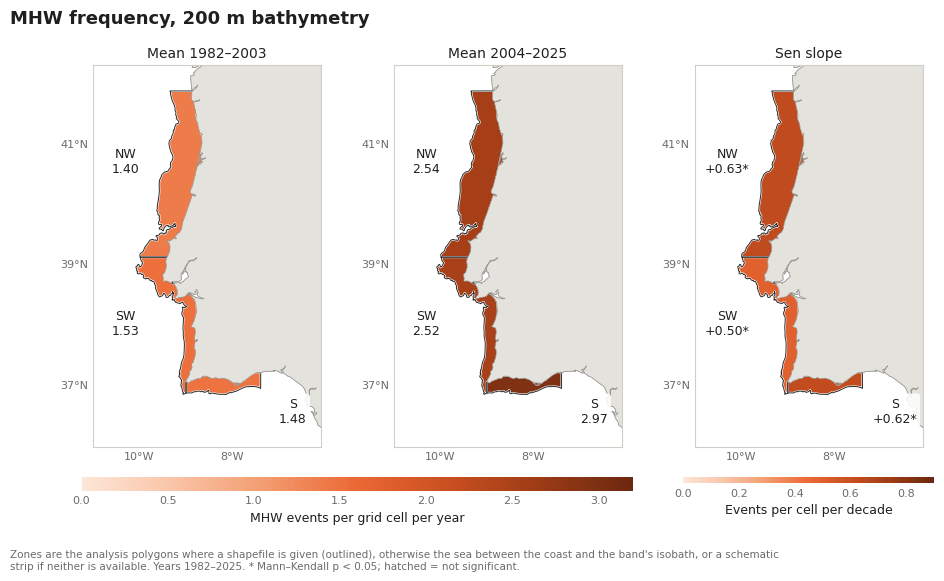

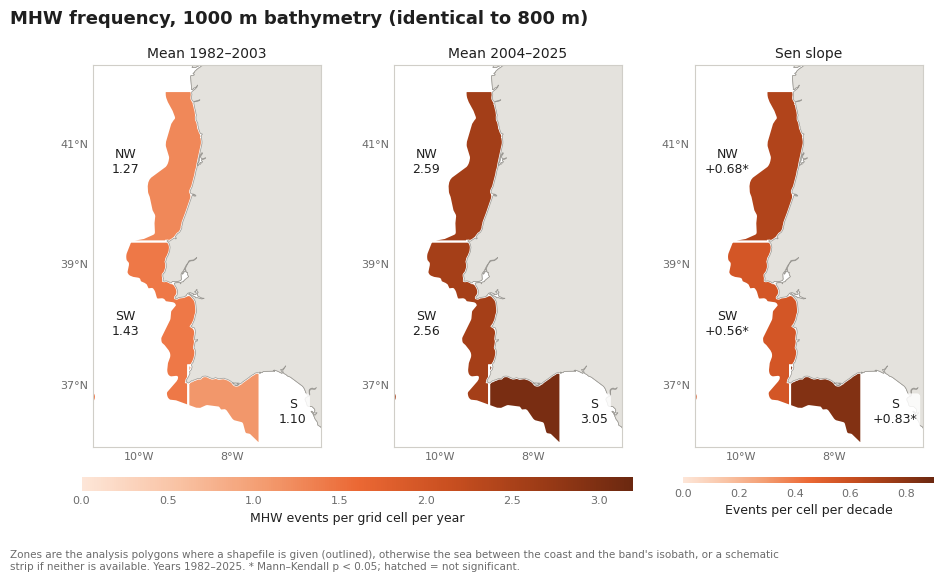

In [7]:
for depth in [d for d in FIG1_DEPTHS if d in D]:
    s = summarise(D[depth], "mean_n_events")
    fig, axes = plt.subplots(1, 3, figsize=(11, 5.6))
    n1, n2 = Normalize(0, 3.2), Normalize(0, 0.9)
    draw_map(axes[0], {z: v["early"] for z, v in s.items()}, n1, "{:.2f}", "Mean 1982–2003", band=depth)
    draw_map(axes[1], {z: v["late"] for z, v in s.items()}, n1, "{:.2f}", "Mean 2004–2025", band=depth)
    colorbar(fig, axes[:2], n1, "MHW events per grid cell per year")
    draw_map(axes[2], {z: v["sen"] for z, v in s.items()}, n2, "+{:.2f}", "Sen slope",
             {z: v["p"] for z, v in s.items()}, band=depth)
    colorbar(fig, axes[2:], n2, "Events per cell per decade")
    fig.suptitle(f"MHW frequency, {depth} m bathymetry{same_note(depth)}",
                 fontsize=13, fontweight="bold", color=INK, x=0.06, ha="left")
    footnote(fig, NOTE + SIG)
    save(fig, f"map1_frequency_{depth}m_early_late_trend.png")

## Figure 2: frequency trend in every bathymetry band

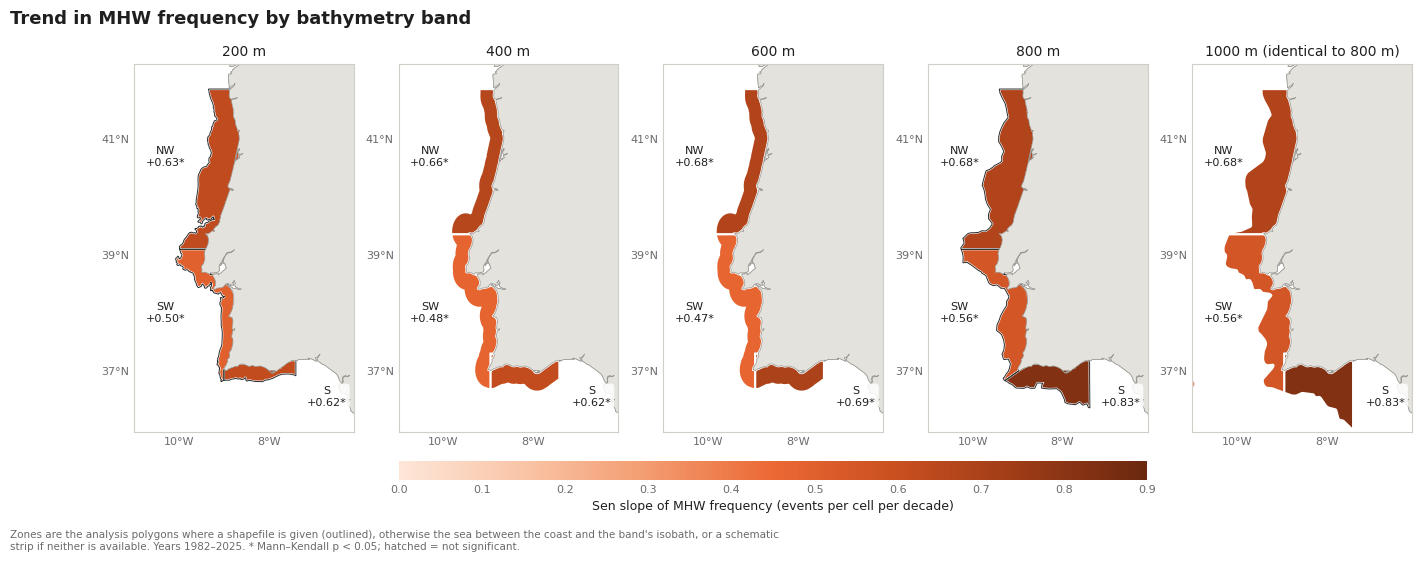

In [8]:
depths = list(D)
fig, axes = plt.subplots(1, len(depths), figsize=(3.3 * len(depths), 5.4))
n2 = Normalize(0, 0.9)
for ax, d in zip(np.atleast_1d(axes), depths):
    s = summarise(D[d], "mean_n_events")
    draw_map(ax, {z: v["sen"] for z, v in s.items()}, n2, "+{:.2f}", f"{d} m{same_note(d)}",
             {z: v["p"] for z, v in s.items()}, fs=8, band=d)
colorbar(fig, list(np.atleast_1d(axes)), n2, "Sen slope of MHW frequency (events per cell per decade)")
fig.suptitle("Trend in MHW frequency by bathymetry band", fontsize=13, fontweight="bold", color=INK, x=0.05, ha="left")
footnote(fig, NOTE + SIG, x=0.05)
save(fig, "map2_frequency_trend_by_depth.png")

## Figure 3: trends in frequency, duration and intensity

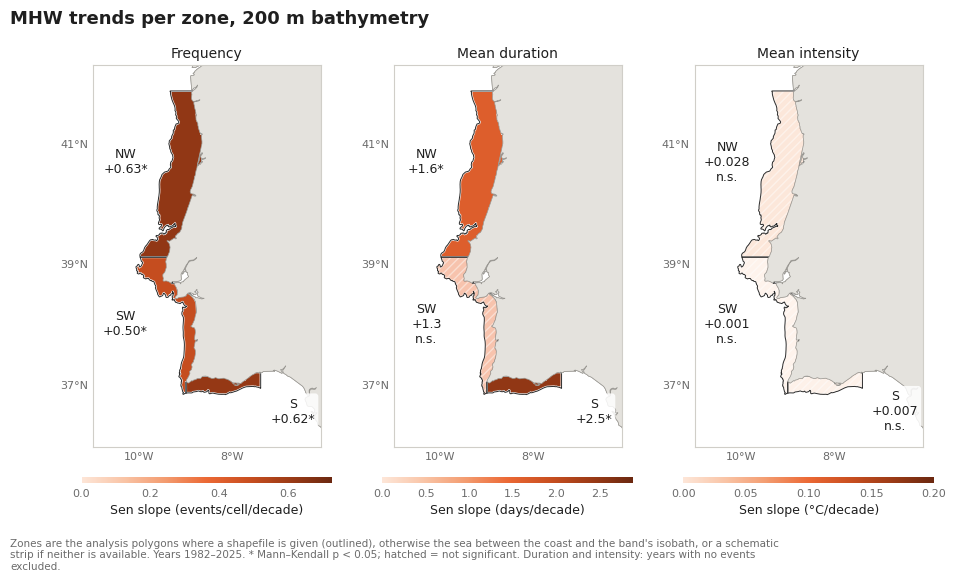

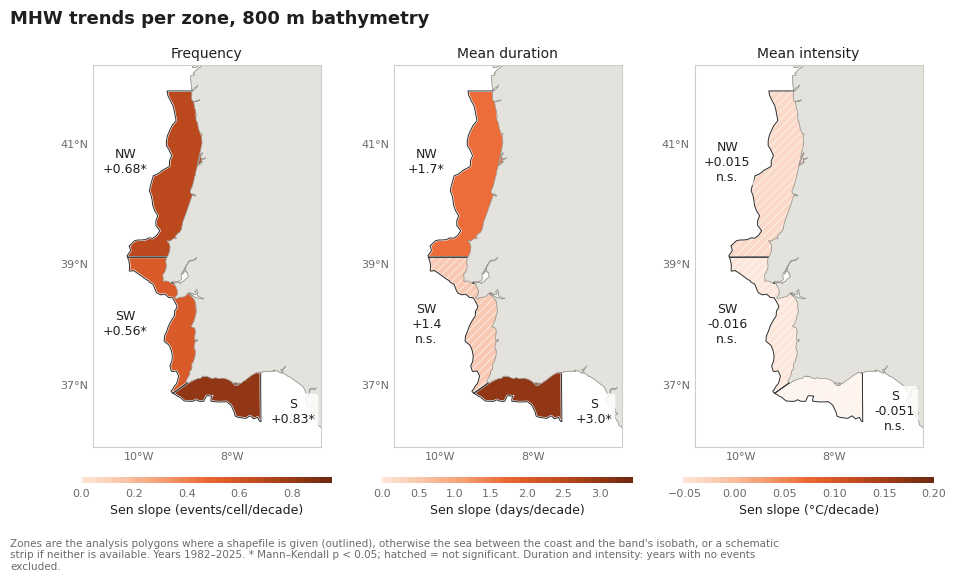

In [9]:
specs = [("mean_n_events", "Frequency", "+{:.2f}", "events/cell/decade"),
         ("mean_duration_days", "Mean duration", "{:+.1f}", "days/decade"),
         ("mean_intensity_degC", "Mean intensity", "{:+.3f}", "°C/decade")]
for depth in [d for d in FIG3_DEPTHS if d in D]:
    fig, axes = plt.subplots(1, 3, figsize=(11, 5.6))
    for ax, (var, name, fmt, unit) in zip(axes, specs):
        s = summarise(D[depth], var)
        vals = {z: v["sen"] for z, v in s.items()}
        lo, hi = min(0, min(vals.values())), max(vals.values()) * 1.15
        if var == "mean_intensity_degC":
            lo, hi = min(lo, 0), 0.2      # fixed scale so tiny non-significant slopes don't look strong
        nn = Normalize(lo, hi if hi > lo else lo + 1)
        draw_map(ax, vals, nn, fmt, name, {z: v["p"] for z, v in s.items()}, band=depth)
        colorbar(fig, [ax], nn, f"Sen slope ({unit})")
    fig.suptitle(f"MHW trends per zone, {depth} m bathymetry{same_note(depth)}",
                 fontsize=13, fontweight="bold", color=INK, x=0.06, ha="left")
    footnote(fig, NOTE + SIG + " Duration and intensity: years with no events excluded.")
    save(fig, f"map3_trends_{depth}m_frequency_duration_intensity.png")

## Figure 3 combined: 200 m vs 800 m on shared colour scales
One report-ready figure: rows = depths in `FIG3_DEPTHS`, columns = frequency, duration, intensity, with panel letters. Colour scales are shared between depths so equal colours mean equal values. The caption is printed below the figure and stored in `CAPTION`.

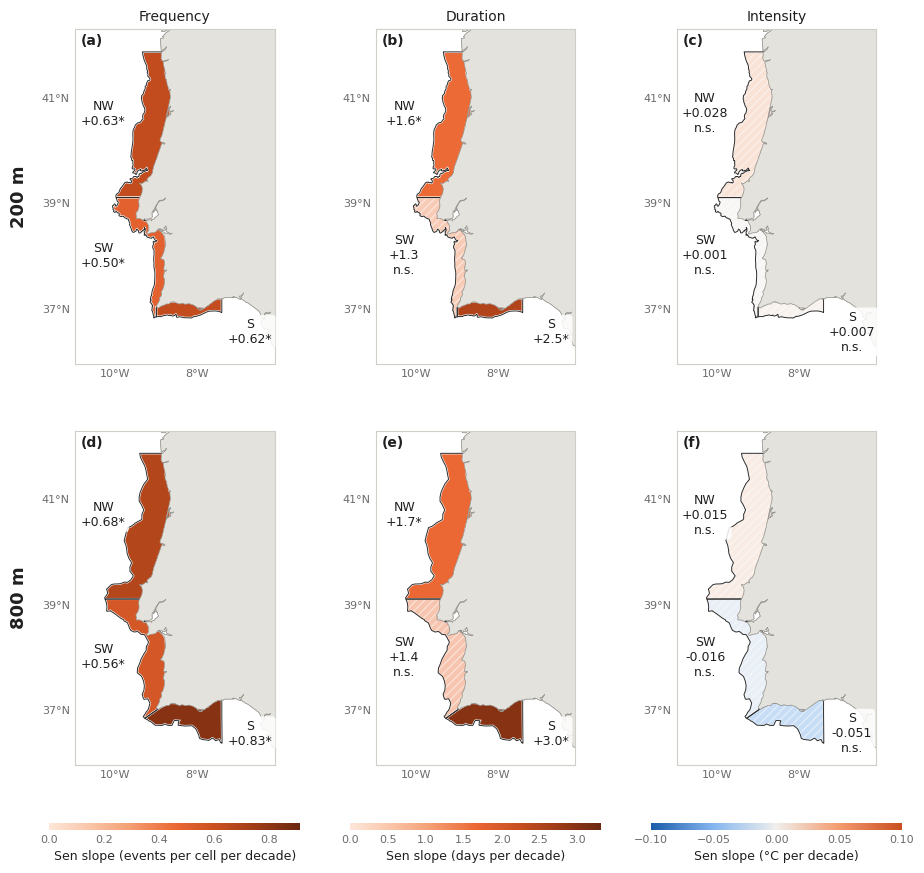

Figure X. Sen slope per decade (1982–2025) of MHW (a, d) frequency (events per grid cell per year), (b, e) duration (days) and (c, f) intensity (°C) for the 200 m and 800 m bands (rows), in the NW, SW and S zones. Zones are the analysis polygons used for each band (outlined). * Mann–Kendall p < 0.05; hatched = not significant.


In [10]:
from matplotlib.colors import TwoSlopeNorm
DIVERGING = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f39b6f", "#c94f20"])
COMBINED_DEPTHS = FIG3_DEPTHS
sen_c = sen_table(COMBINED_DEPTHS)
cols = [("Frequency", "+{:.2f}", "events per cell per decade", None),
        ("Duration", "{:+.1f}", "days per decade", None),
        ("Intensity", "{:+.3f}", "°C per decade", DIVERGING)]
fig, axes = plt.subplots(len(COMBINED_DEPTHS), 3, figsize=(11, 5.0 * len(COMBINED_DEPTHS) + 0.8), squeeze=False)
for c, (name, fmt, unit, cm) in enumerate(cols):
    sub = sen_c[sen_c.metric == name]
    if cm is None:                       # one shared sequential scale per metric across depths
        norm = Normalize(min(0, sub.sen_slope_per_decade.min()), sub.sen_slope_per_decade.max() * 1.1)
    else:                                # intensity: diverging around zero, symmetric
        m = max(0.1, sub.sen_slope_per_decade.abs().max() * 1.2)
        norm = TwoSlopeNorm(0, -m, m)
    for r, depth in enumerate(COMBINED_DEPTHS):
        t = sub[sub.depth_m == depth].set_index("zone")
        draw_map(axes[r, c], t.sen_slope_per_decade.to_dict(), norm, fmt,
                 name if r == 0 else "", t.mk_p.to_dict(), band=depth, show_key=False, cmap=cm)
        if c == 0:
            axes[r, c].set_ylabel(f"{depth} m", fontsize=13, fontweight="bold", color=INK, labelpad=10)
        axes[r, c].text(0.03, 0.985, f"({'abcdefghi'[r * 3 + c]})", transform=axes[r, c].transAxes,
                        fontsize=10, fontweight="bold", color=INK, va="top", zorder=6)
    colorbar(fig, list(axes[:, c]), norm, f"Sen slope ({unit})", cmap=cm)
save(fig, f"fig_trends_{'_vs_'.join(f'{d}m' for d in COMBINED_DEPTHS)}_combined.png", dpi=300)

CAPTION = (
    "Figure X. Sen slope per decade (1982–2025) of MHW (a, d) frequency (events per grid cell per year), "
    "(b, e) duration (days) and (c, f) intensity (°C) for the "
    + " and ".join(f"{d} m" for d in COMBINED_DEPTHS) +
    " bands (rows), in the NW, SW and S zones. "
    + ("Zones are the analysis polygons used for each band (outlined). "
       if all(d in ZONES_FROM_SHP for d in COMBINED_DEPTHS) else "Zone outlines are schematic. ")
    + "* Mann–Kendall p < 0.05; hatched = not significant."
)
print(CAPTION)

## Figure 4: frequency, duration and intensity per period

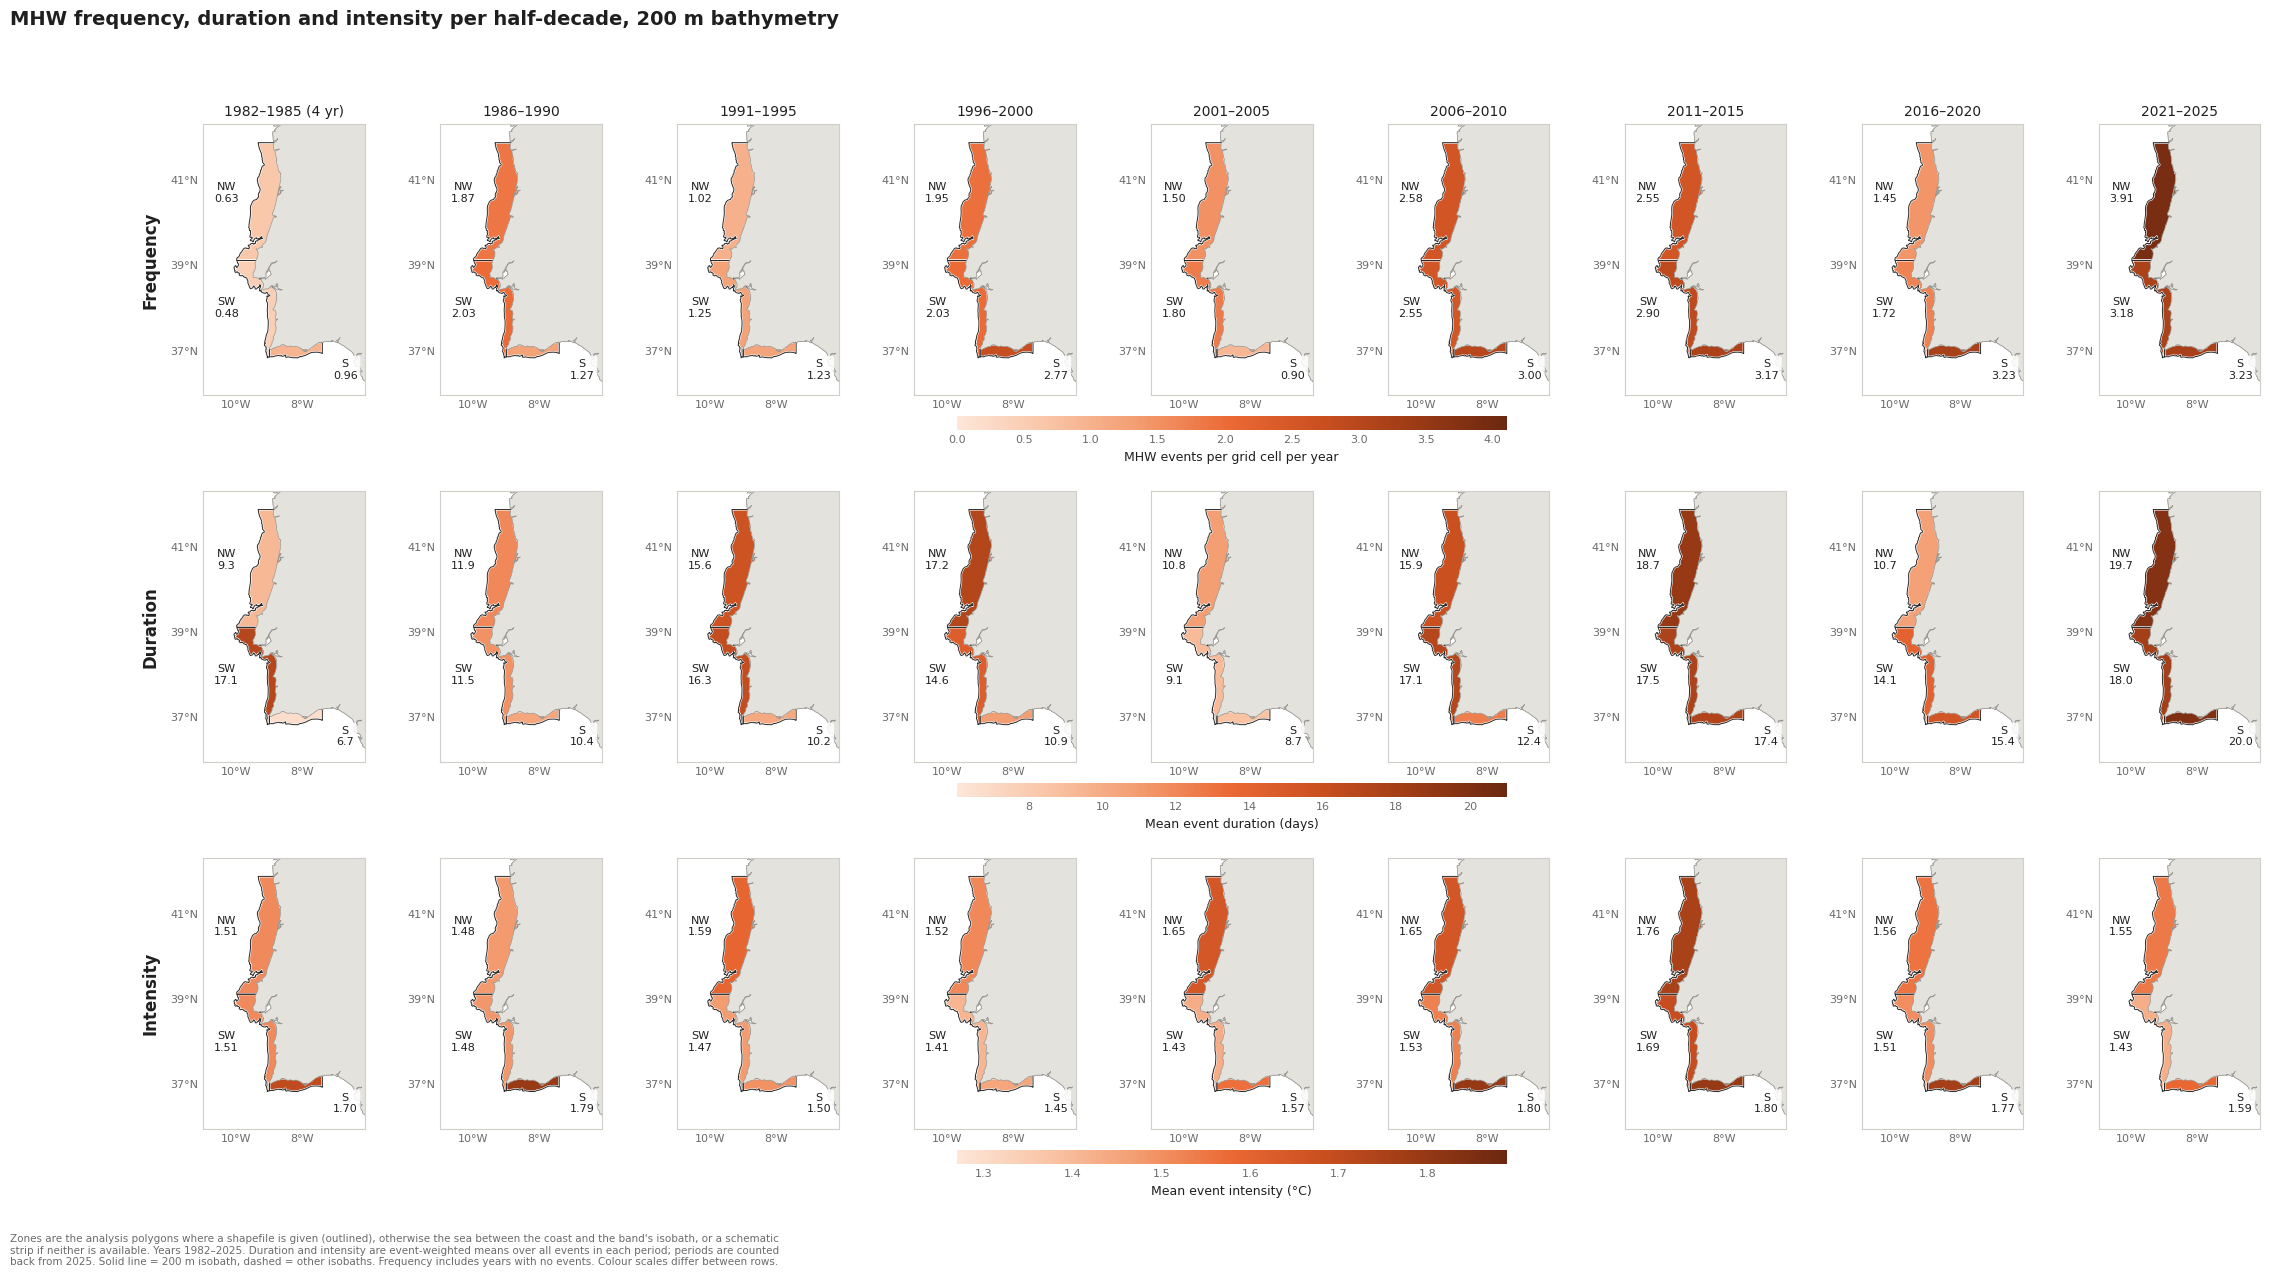

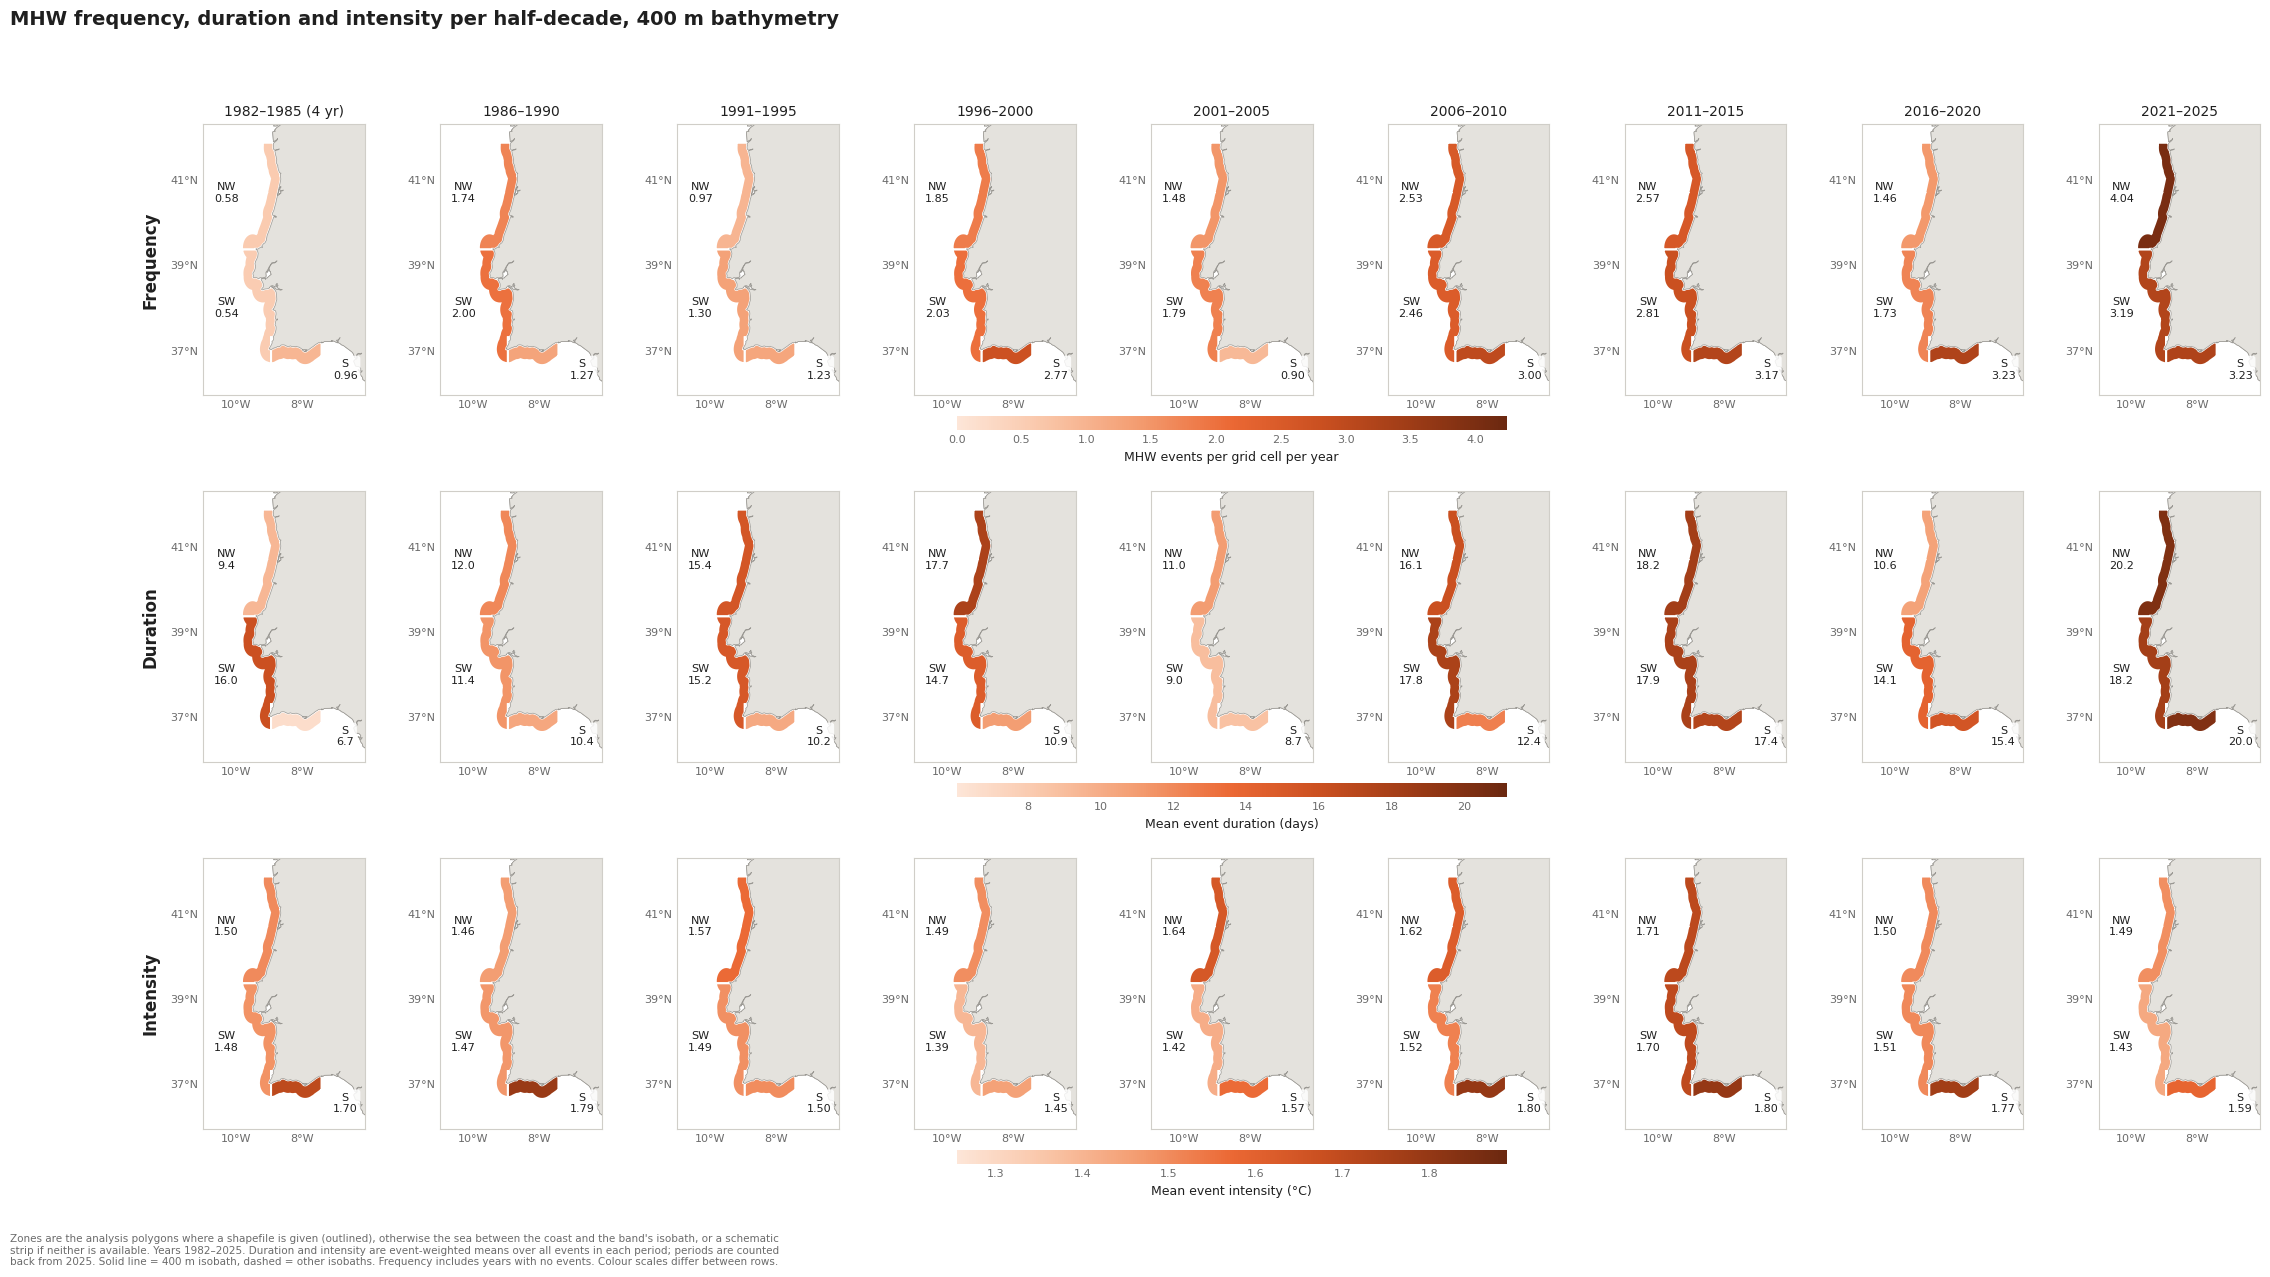

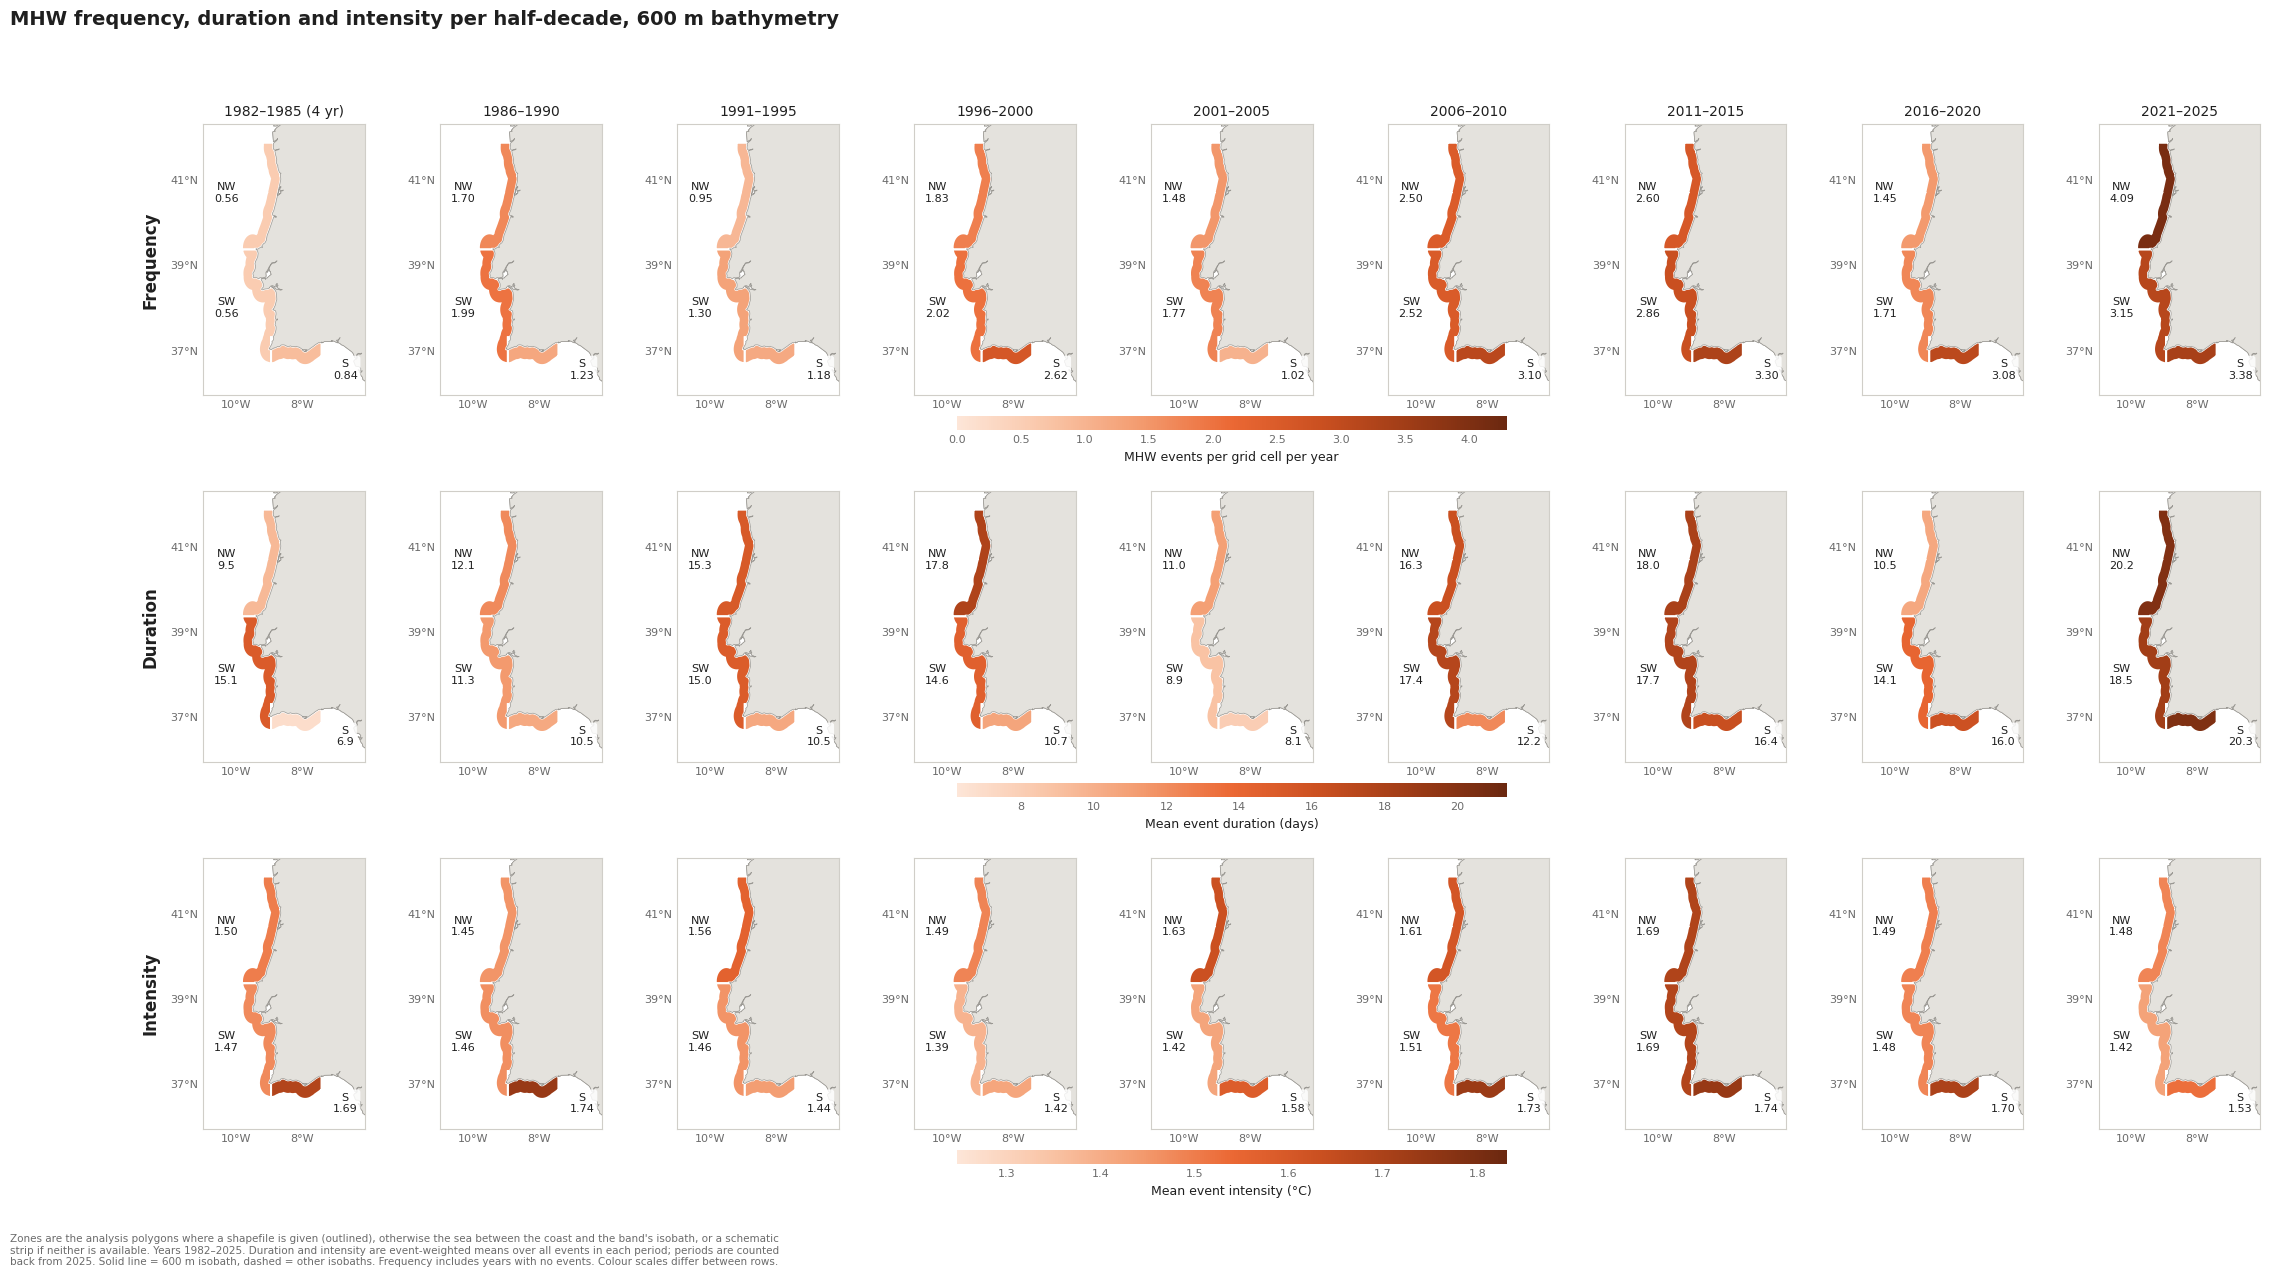

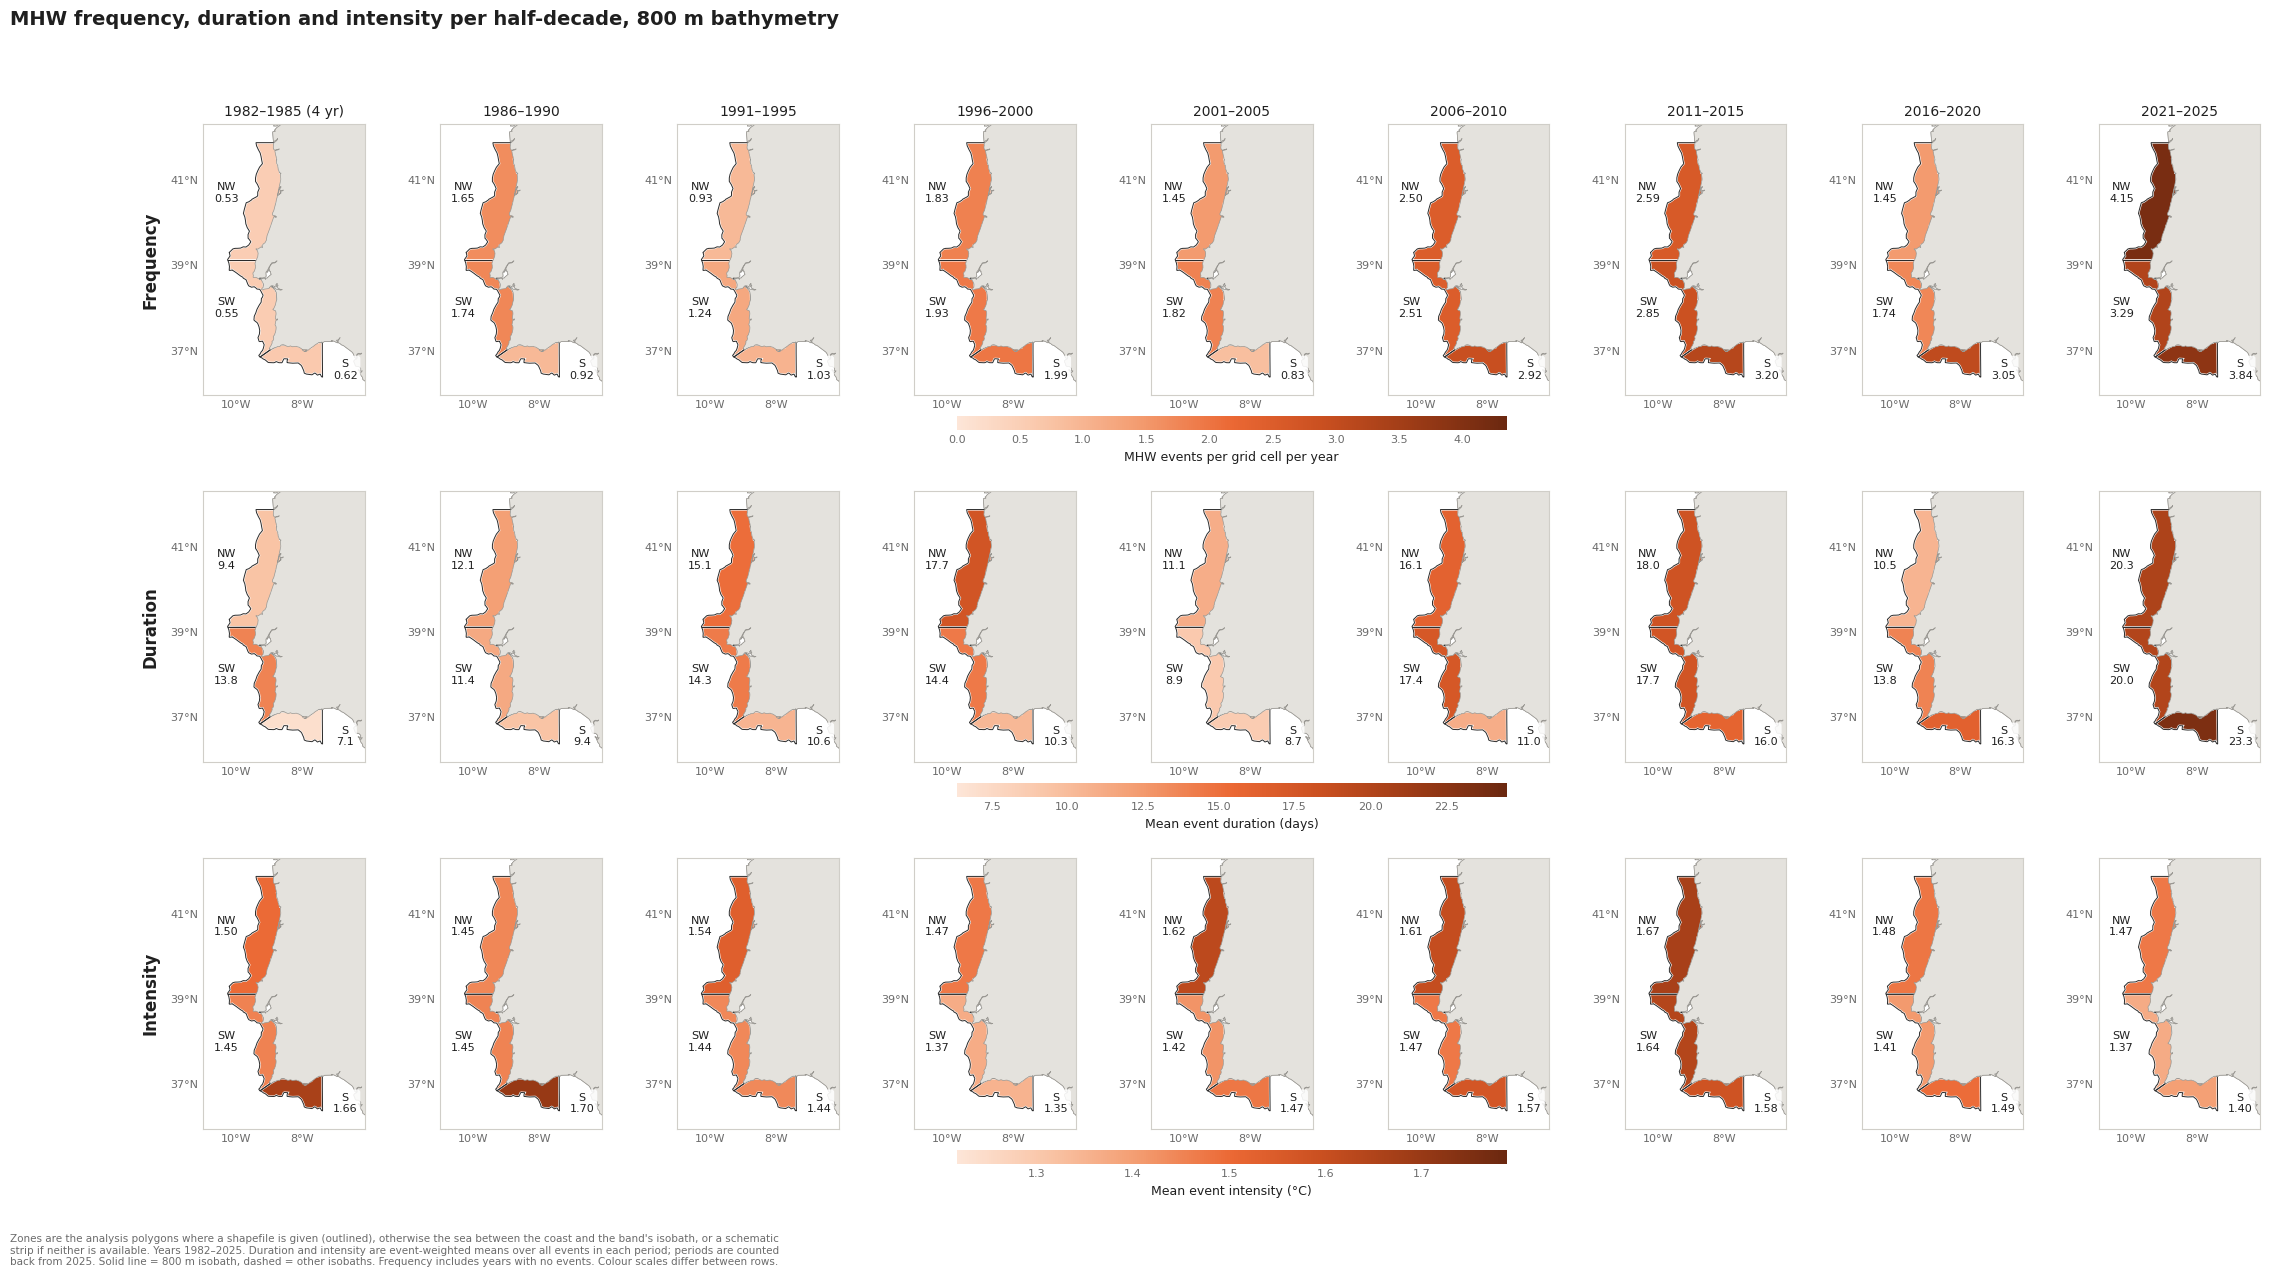

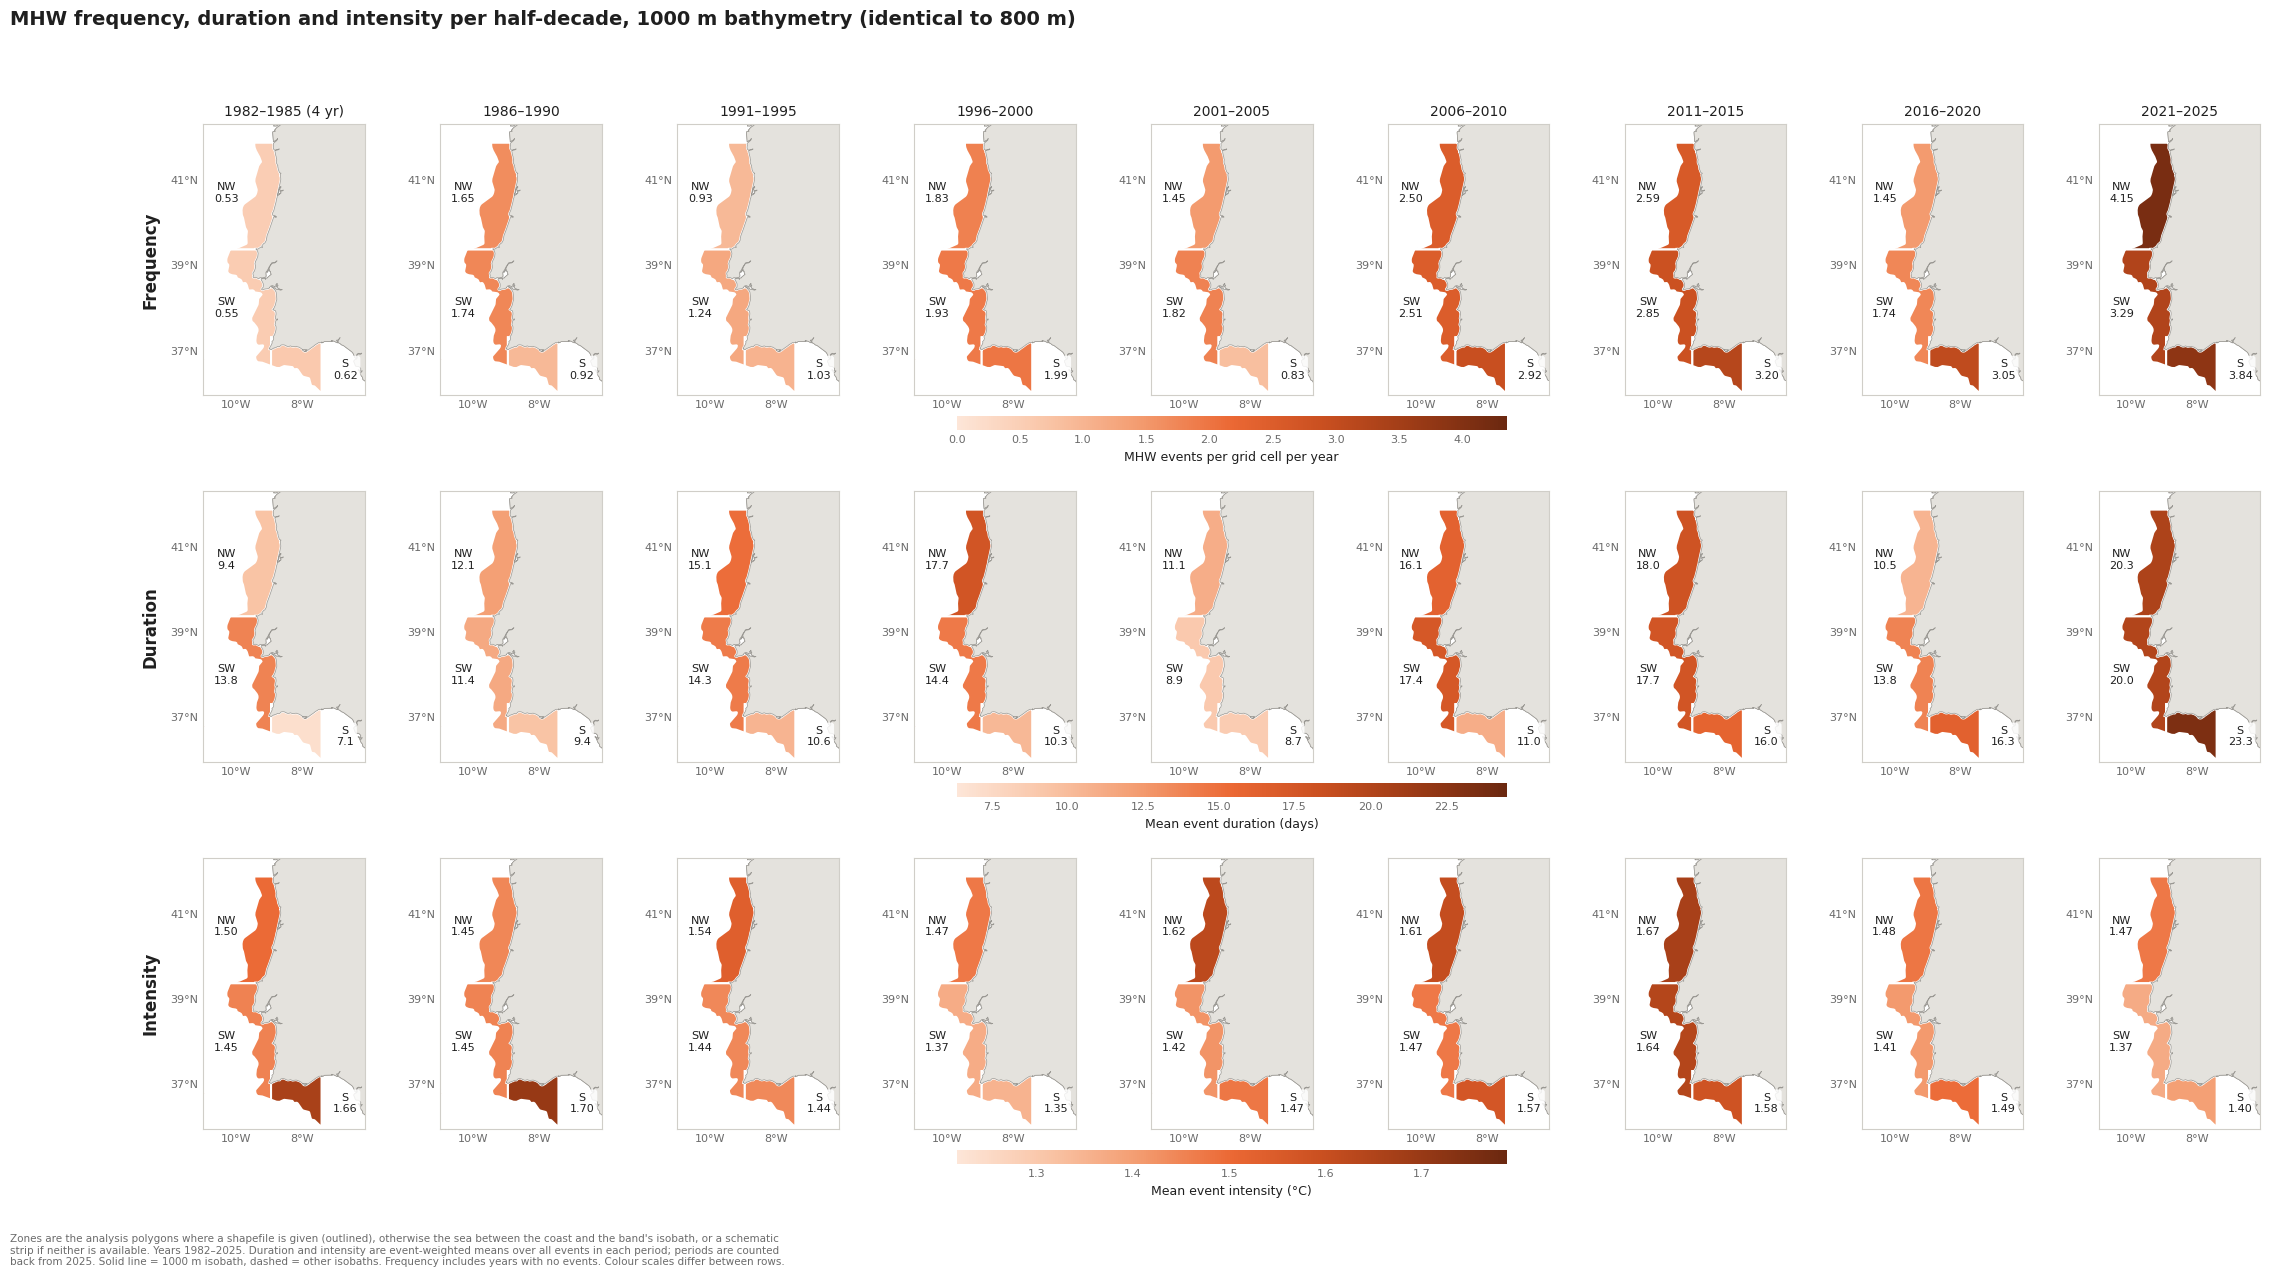

In [11]:
rows = [("freq", "Frequency", "{:.2f}", "MHW events per grid cell per year"),
        ("dur", "Duration", "{:.1f}", "Mean event duration (days)"),
        ("inten", "Intensity", "{:.2f}", "Mean event intensity (°C)")]
for depth in D:
    dec = decadal(D[depth])
    nc = len(dec)
    fig, axes = plt.subplots(3, nc, figsize=(3.0 * nc, 13.5), squeeze=False)
    for r, (key, name, fmt, label) in enumerate(rows):
        vals = [v[key] for d in dec.values() for v in d.values()]
        norm = Normalize(0 if key == "freq" else min(vals) * 0.9, max(vals) * 1.05)
        for c, (period, zv) in enumerate(dec.items()):
            yrs = period[1] - period[0] + 1
            ttl = f"{period[0]}–{period[1]}" + (f" ({yrs} yr)" if yrs < PERIOD_YEARS else "")
            draw_map(axes[r, c], {z: zv[z][key] for z in zv}, norm, fmt, ttl if r == 0 else "", fs=8,
                     band=depth, show_key=False)
        axes[r, 0].set_ylabel(name, fontsize=12, fontweight="bold", color=INK, labelpad=8)
        colorbar(fig, list(axes[r]), norm, label)
    unit = {5: "half-decade", 10: "decade"}.get(PERIOD_YEARS, f"{PERIOD_YEARS}-year period")
    fig.suptitle(f"MHW frequency, duration and intensity per {unit}, {depth} m bathymetry{same_note(depth)}",
                 fontsize=14, fontweight="bold", color=INK, x=0.06, ha="left", y=0.965)
    footnote(fig, NOTE + " Duration and intensity are event-weighted means over all events in each period; periods are counted back from 2025. "
             f"Solid line = {depth} m isobath, dashed = other isobaths. Frequency includes years with no events. Colour scales differ between rows.", y=0.035)
    save(fig, f"map4_{PERIOD_YEARS}yr_periods_{depth}m.png", dpi=170)

## Figure 5: time series with Sen slope trend lines, depths compared
Annual values and Theil–Sen trend lines for the depths in `SLOPE_DEPTHS`, one panel per metric and zone, with the slope per decade [95% CI] in each panel.

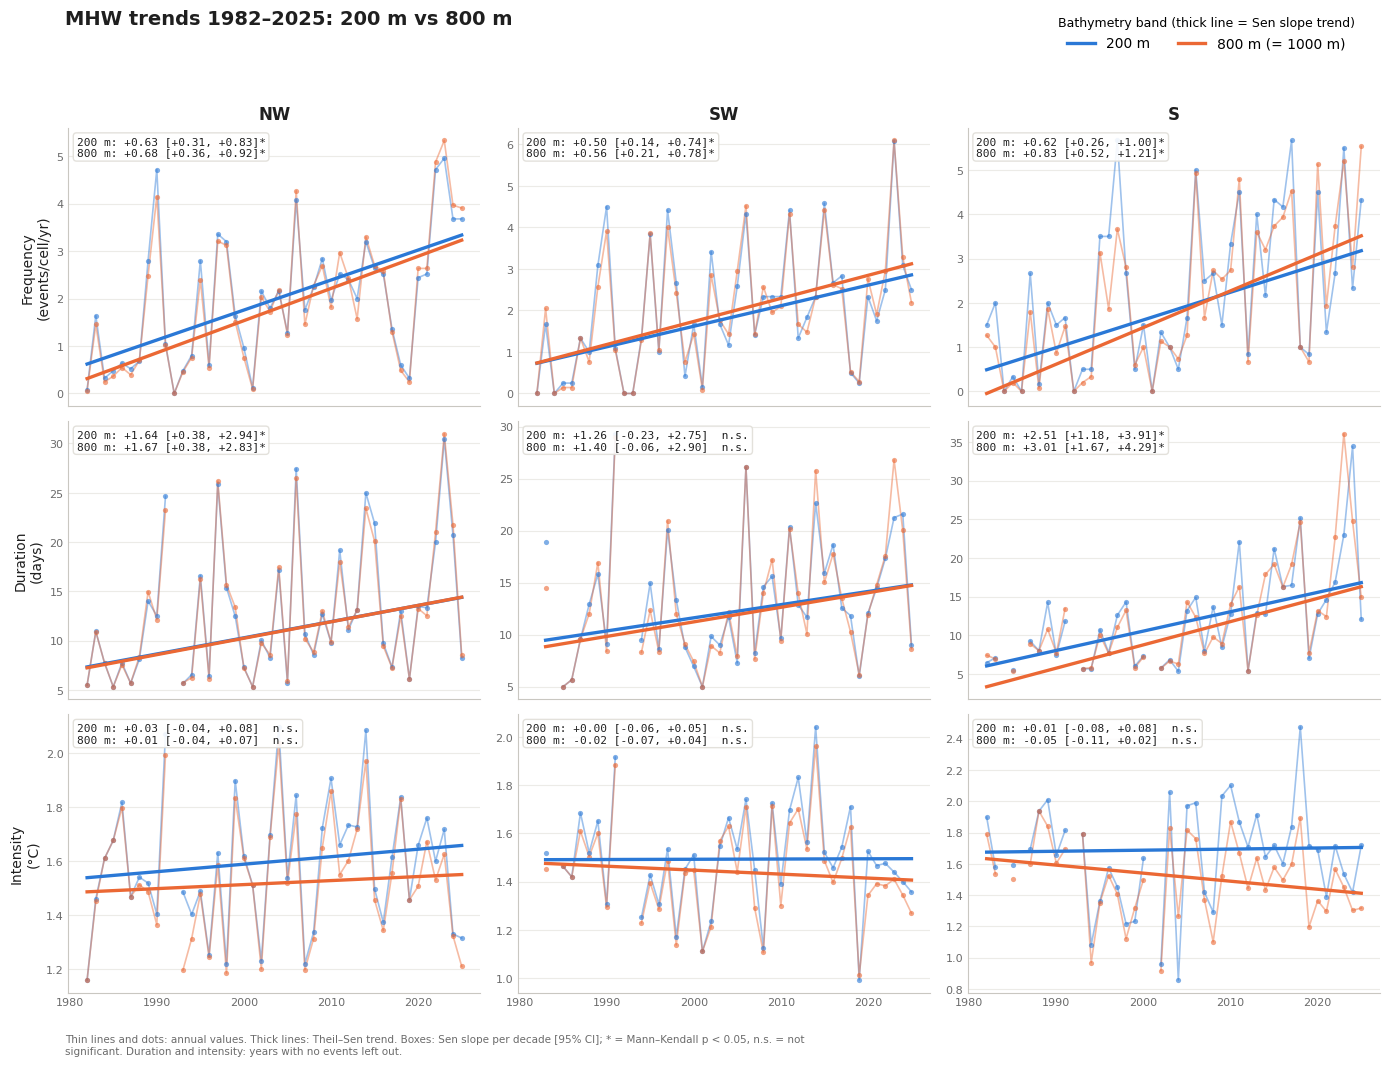

In [12]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed categorical order
DEPTH_COLOR = {d: SERIES_COLORS[i] for i, d in enumerate(SLOPE_DEPTHS)}

fig, axes = plt.subplots(3, 3, figsize=(14, 10.5), sharex=True)
for r, (var, (name, unit)) in enumerate(METRICS.items()):
    for c, z in enumerate(["NW", "SW", "S"]):
        ax = axes[r, c]
        notes = []
        for depth in SLOPE_DEPTHS:
            col = DEPTH_COLOR[depth]
            s = D[depth][D[depth].Zone == z].sort_values("Year")
            ax.plot(s.Year, s[var], color=col, lw=1.2, alpha=0.45, zorder=2)
            ax.scatter(s.Year, s[var], s=14, color=col, alpha=0.6, lw=0, zorder=3)
            ok = s.dropna(subset=[var])
            slope, icpt, _, _ = stats.theilslopes(ok[var], ok.Year)
            yrs = np.array([ok.Year.min(), ok.Year.max()])
            ax.plot(yrs, icpt + slope * yrs, color=col, lw=2.4, zorder=4,
                    label=f"{depth} m" + (" (= 1000 m)" if SAME_AS.get(1000) == depth else ""))
            row = sen[(sen.depth_m == depth) & (sen.metric == name) & (sen.zone == z)].iloc[0]
            notes.append(f"{depth} m: {row.sen_slope_per_decade:+.2f} [{row.ci95_low:+.2f}, {row.ci95_high:+.2f}]"
                         + ("*" if row.significant else "  n.s."))
        ax.text(0.02, 0.97, "\n".join(notes), transform=ax.transAxes, va="top", fontsize=8, color=INK,
                family="monospace", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#e0ded8", alpha=0.9))
        ax.grid(axis="y", color="#ecebe7", lw=0.8); ax.set_axisbelow(True)
        for sp in ["top", "right"]:
            ax.spines[sp].set_visible(False)
        for sp in ["left", "bottom"]:
            ax.spines[sp].set_color("#c9c7c1")
        ax.tick_params(colors=MUTED, labelsize=8, length=0)
        if r == 0:
            ax.set_title(z, fontsize=12, fontweight="bold", color=INK)
        if c == 0:
            ax.set_ylabel(f"{name}\n({ {'Frequency': 'events/cell/yr', 'Duration': 'days', 'Intensity': '°C'}[name] })",
                          fontsize=10, color=INK)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=len(SLOPE_DEPTHS), frameon=False, fontsize=10,
           title="Bathymetry band (thick line = Sen slope trend)", title_fontsize=9, bbox_to_anchor=(0.98, 1.0))
fig.suptitle("MHW trends 1982–2025: " + " vs ".join(f"{d} m" for d in SLOPE_DEPTHS),
             fontsize=14, fontweight="bold", color=INK, x=0.05, ha="left", y=0.995)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
footnote(fig, "Thin lines and dots: annual values. Thick lines: Theil–Sen trend. Boxes: Sen slope per decade "
         "[95% CI]; * = Mann–Kendall p < 0.05, n.s. = not significant. Duration and intensity: years with no "
         "events left out.", x=0.05, y=0.0)
save(fig, f"trends_timeseries_{'_vs_'.join(f'{d}m' for d in SLOPE_DEPTHS)}.png")

## Figure 6: Sen slopes side by side, depths compared
Sen slope per decade with 95% CI for each depth, zone and metric. Filled = significant (Mann–Kendall p < 0.05).

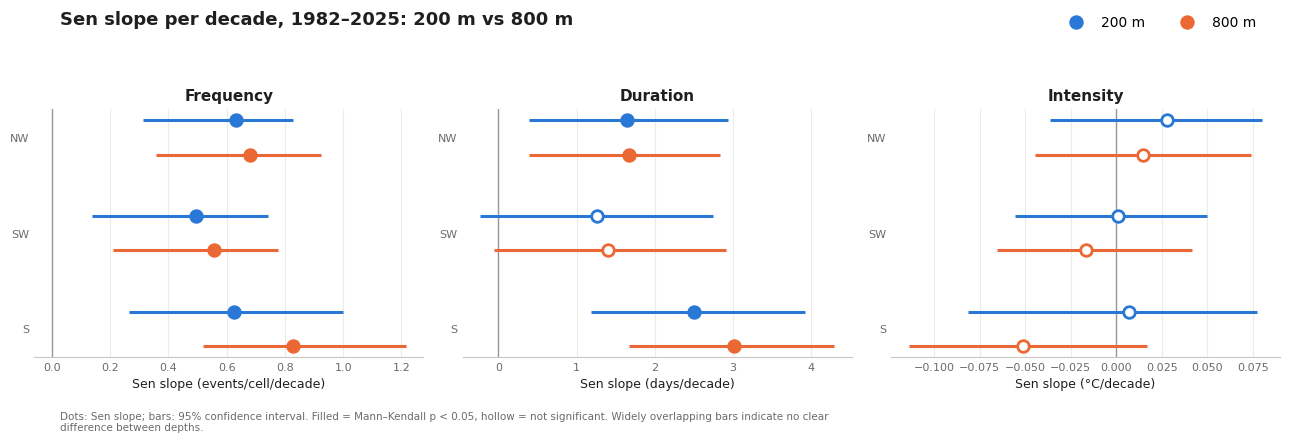

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
zones = ["NW", "SW", "S"]
off = np.linspace(-0.18, 0.18, len(SLOPE_DEPTHS)) if len(SLOPE_DEPTHS) > 1 else [0]
for ax, (var, (name, unit)) in zip(axes, METRICS.items()):
    ax.axvline(0, color="#9a9893", lw=1, zorder=1)
    for k, depth in enumerate(SLOPE_DEPTHS):
        col = DEPTH_COLOR[depth]
        t = sen[(sen.depth_m == depth) & (sen.metric == name)].set_index("zone").loc[zones]
        y = np.arange(len(zones)) + off[k]
        ax.hlines(y, t.ci95_low, t.ci95_high, color=col, lw=2.2, zorder=2)
        for yi, (_, rr) in zip(y, t.iterrows()):
            ax.scatter(rr.sen_slope_per_decade, yi, s=70, zorder=3, color=col if rr.significant else "white",
                       edgecolor=col, lw=2, label=f"{depth} m" if yi == y[0] else None)
    ax.set_yticks(range(len(zones))); ax.set_yticklabels(zones, fontsize=10, color=INK)
    ax.invert_yaxis()
    ax.set_title(name, fontsize=11, fontweight="bold", color=INK)
    ax.set_xlabel(f"Sen slope ({unit})", fontsize=9, color=INK)
    ax.grid(axis="x", color="#ecebe7", lw=0.8); ax.set_axisbelow(True)
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color("#c9c7c1")
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=len(SLOPE_DEPTHS), frameon=False, fontsize=10,
           bbox_to_anchor=(0.98, 1.02))
fig.suptitle("Sen slope per decade, 1982–2025: " + " vs ".join(f"{d} m" for d in SLOPE_DEPTHS),
             fontsize=13, fontweight="bold", color=INK, x=0.05, ha="left", y=1.0)
fig.tight_layout(rect=(0, 0.06, 1, 0.93))
footnote(fig, "Dots: Sen slope; bars: 95% confidence interval. Filled = Mann–Kendall p < 0.05, hollow = not "
         "significant. Widely overlapping bars indicate no clear difference between depths.", x=0.05, y=0.0)
save(fig, f"sen_slopes_compare_{'_vs_'.join(f'{d}m' for d in SLOPE_DEPTHS)}.png")